# Synthetic Benchmark Data: Generation and Exploration

This notebook is the **single source of truth for the synthetic benchmark corpora** used by Polarized Trees.

It has four jobs:

1. define the benchmark regimes: the three from the paper (A, B, C) and seven more (D to J), all used by the hyperparameter search;
2. generate each corpus **once** with a fixed seed;
3. inspect the generated data and its ground truth;
4. save the datasets and ground truth so the benchmark notebook can reuse exactly the same data for every hyperparameter configuration.

The benchmark corpora are A (default), B (weak signal), and C (deep intersectional), plus D (strong signal), E (very weak), F (shallow), G (uniform depth), H (deep, weak), I (deep, strong) and J (shallow, weak). A separate **unseen inference corpus** is also generated with the A/default regime and a new seed. The benchmark notebook uses all ten corpora (A to J) for model selection and uses the unseen corpus only after model selection, matching the paper's train/validation → inference logic.

## 1. Imports and configuration

The generator is imported from `polartox.datagen`; the notebook does not redefine `AnnotatorPool`.

The benchmark settings below are the ones reported in the paper.

In [2]:
# If running from a clean environment, install the local package once:
# %pip install -e ..


In [3]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [4]:
# ------------------------------------------------------------
# Locate project root
# ------------------------------------------------------------

CWD = Path.cwd().resolve()

if (CWD / "benchmark_config.py").exists():
    PROJECT_ROOT = CWD
elif (CWD.parent / "benchmark_config.py").exists():
    PROJECT_ROOT = CWD.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. "
        "Expected benchmark_config.py in the current "
        "directory or its parent."
    )


if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [5]:
# ------------------------------------------------------------
# Package imports
# ------------------------------------------------------------

from polartox.datagen import AnnotatorPool

from benchmark_config import (
    DATA_DIR,
    DIMS_DICT,
    DIMS,
    SCALE,
    N_TEXTS,
    ANNOTATORS_PER_IDENTITY,
    NOISE,
    CORPUS_CONFIGS,
    ALL_CORPUS_CONFIGS,
    EVALUATION_CORPORA,
    INFERENCE_CONFIG,
)


# ------------------------------------------------------------
# Project directories
# ------------------------------------------------------------

DATA_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_DIR = DATA_DIR


# ------------------------------------------------------------
# Configuration summary
# ------------------------------------------------------------

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

print("Dimensions:", DIMS)

print(
    "Search corpora (A to J):",
    [c["name"] for c in ALL_CORPUS_CONFIGS],
)

print(
    "All evaluation corpora:",
    EVALUATION_CORPORA,
)

print(
    "Inference corpus:",
    INFERENCE_CONFIG["name"],
)

Project root: C:\Users\Sokratis\OneDrive\Υπολογιστής\ερευνα\HumanModelAlign\polarizedtrees\benchmarks
Data directory: C:\Users\Sokratis\OneDrive\Υπολογιστής\ερευνα\HumanModelAlign\polarizedtrees\benchmarks\benchmark_data
Dimensions: ['gender', 'politics', 'age', 'education', 'orientation']
Search corpora (A to J): ['A_default', 'B_weak_signal', 'C_deep', 'D_strong_signal', 'E_very_weak', 'F_shallow', 'G_uniform_depth', 'H_deep_weak', 'I_deep_strong', 'J_shallow_weak']
All evaluation corpora: ['A_default', 'B_weak_signal', 'C_deep', 'D_strong_signal', 'E_very_weak', 'F_shallow', 'G_uniform_depth', 'H_deep_weak', 'I_deep_strong', 'J_shallow_weak']
Inference corpus: inference_unseen


## 2. Visualize the intended benchmark regimes

This reproduces the paper's benchmark-distribution view: latent polarization strength on the top row and interaction depth `k` on the bottom row.

These are the **sampling distributions specified by the benchmark**, not a second dataset-generation process. The actual generated corpora are inspected below.

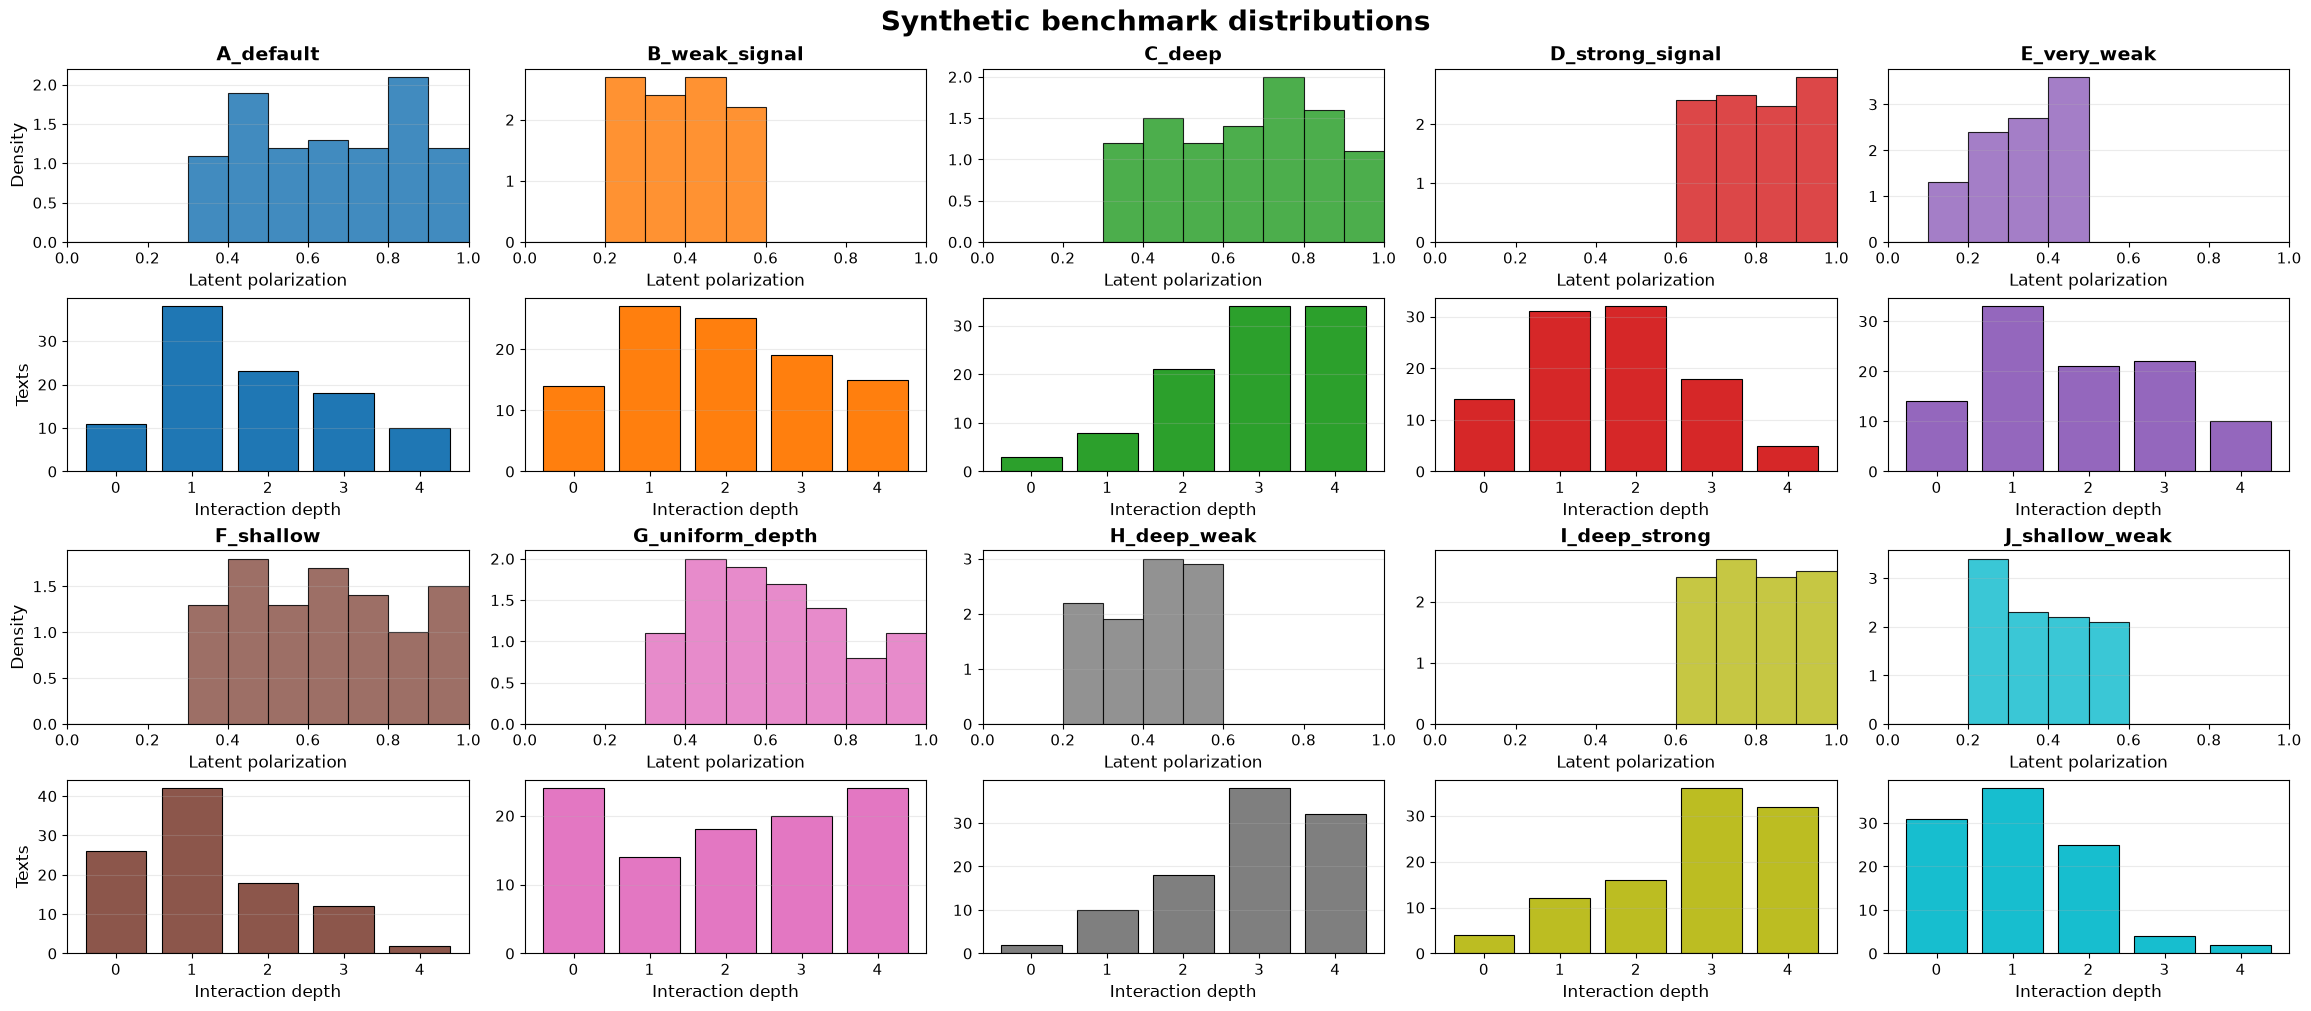

In [19]:
colors = plt.cm.tab10.colors
depths = [0, 1, 2, 3, 4]

N_COLS = 5
n_blocks = -(-len(ALL_CORPUS_CONFIGS) // N_COLS)

fig, axes = plt.subplots(
    2 * n_blocks, N_COLS,
    figsize=(4.6 * N_COLS, 5.0 * n_blocks),
    constrained_layout=True,
    squeeze=False,
)

for idx, cfg in enumerate(ALL_CORPUS_CONFIGS):
    block, col = divmod(idx, N_COLS)
    rng = np.random.default_rng(cfg["seed"])

    intensities = rng.uniform(
        cfg["intensity_range"][0],
        cfg["intensity_range"][1],
        size=N_TEXTS,
    )

    sampled_depths = rng.choice(
        depths,
        size=N_TEXTS,
        p=[cfg["depth_weights"][d] for d in depths],
    )

    # Top row of the block: latent polarization
    ax = axes[2 * block, col]
    ax.hist(
        intensities,
        bins=10,
        range=(0, 1),
        density=True,
        color=colors[idx],
        edgecolor="black",
        linewidth=0.8,
        alpha=0.85,
    )
    ax.set_xlim(0, 1)
    ax.set_title(cfg["name"], fontsize=14, fontweight="bold")
    ax.set_xlabel("Latent polarization", fontsize=12)
    ax.tick_params(labelsize=11)
    if col == 0:
        ax.set_ylabel("Density", fontsize=12)
    ax.grid(axis="y", alpha=0.25)

    # Bottom row of the block: interaction depth
    ax = axes[2 * block + 1, col]
    counts = [np.sum(sampled_depths == d) for d in depths]
    ax.bar(
        depths,
        counts,
        width=0.8,
        color=colors[idx],
        edgecolor="black",
        linewidth=0.8,
    )
    ax.set_xticks(depths)
    ax.set_xlabel("Interaction depth", fontsize=12)
    ax.tick_params(labelsize=11)
    if col == 0:
        ax.set_ylabel("Texts", fontsize=12)
    ax.grid(axis="y", alpha=0.25)

# hide the unused panels of the last block
for idx in range(len(ALL_CORPUS_CONFIGS), n_blocks * N_COLS):
    block, col = divmod(idx, N_COLS)
    axes[2 * block, col].axis("off")
    axes[2 * block + 1, col].axis("off")

fig.suptitle(
    "Synthetic benchmark distributions",
    fontsize=20,
    fontweight="bold",
)

plt.show()


## 3. Generate the benchmark and inference corpora (A to J, and the unseen one)

Each corpus is generated **once**. The resulting datasets are reused unchanged by the benchmark notebook, so a hyperparameter comparison is not confounded by resampling the annotations.

Ground truth is retained only for synthetic recovery evaluation. The inference corpus is saved with its ground truth for optional post-hoc checking, but the benchmark notebook intentionally does **not** pass that ground truth to Polarized Trees during inference.

In [7]:
def generate_corpus(cfg):
    pool = AnnotatorPool(
        dimensions=DIMS_DICT,
        scale=SCALE,
        intensity_range=cfg["intensity_range"],
        depth_weights=cfg["depth_weights"],
        annotators_per_identity=ANNOTATORS_PER_IDENTITY,
    )

    dataset, ground_truth = pool.generate_dataset(
        n_texts=N_TEXTS,
        n_annotators_per_text=None,
        noise=NOISE,
        seed=cfg["seed"],
    )

    return pool, dataset, ground_truth


def json_safe(obj):
    if isinstance(obj, dict):
        return {str(k): json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [json_safe(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    return obj


corpora = {}

for cfg in ALL_CORPUS_CONFIGS + [INFERENCE_CONFIG]:
    pool, dataset, ground_truth = generate_corpus(cfg)

    name = cfg["name"]
    corpora[name] = {
        "dataset": dataset,
        "ground_truth": ground_truth,
        "config": cfg,
        "pool_size": pool.pool_size,
        "n_identities": pool.n_identities,
    }

    dataset.to_csv(OUTPUT_DIR / f"{name}_dataset.csv", index=False)
    with open(OUTPUT_DIR / f"{name}_ground_truth.json", "w") as f:
        json.dump(json_safe(ground_truth), f, indent=2)

    with open(OUTPUT_DIR / f"{name}_config.json", "w") as f:
        json.dump(json_safe(cfg), f, indent=2)

    print(
        f"{name}: {len(dataset):,} annotations | "
        f"{dataset['text_id'].nunique()} texts | "
        f"{dataset['annotator_id'].nunique()} annotators"
    )

print("\nSaved corpora to:", OUTPUT_DIR.resolve())

A_default: 162,000 annotations | 100 texts | 1620 annotators
B_weak_signal: 162,000 annotations | 100 texts | 1620 annotators
C_deep: 162,000 annotations | 100 texts | 1620 annotators
D_strong_signal: 162,000 annotations | 100 texts | 1620 annotators
E_very_weak: 162,000 annotations | 100 texts | 1620 annotators
F_shallow: 162,000 annotations | 100 texts | 1620 annotators
G_uniform_depth: 162,000 annotations | 100 texts | 1620 annotators
H_deep_weak: 162,000 annotations | 100 texts | 1620 annotators
I_deep_strong: 162,000 annotations | 100 texts | 1620 annotators
J_shallow_weak: 162,000 annotations | 100 texts | 1620 annotators
inference_unseen: 162,000 annotations | 100 texts | 1620 annotators

Saved corpora to: C:\Users\Sokratis\OneDrive\Υπολογιστής\ερευνα\HumanModelAlign\polarizedtrees\benchmarks\benchmark_data


## 4. Basic corpus inspection

Before running Polarized Trees, check that the generated datasets have the expected size, dimensions, annotation counts, and ground-truth depth distribution.

In [18]:
for name, item in corpora.items():
    dataset = item["dataset"]
    gt = item["ground_truth"]

    k = pd.Series(
        {text_id: len(gt[text_id]["active_dims"]) for text_id in gt},
        name="k",
    )

    print(f"\n{name}")
    print("-" * len(name))
    print("Shape:", dataset.shape)
    print("Annotations/text:", dataset.groupby("text_id").size().describe().loc[["min", "mean", "max"]].to_dict())
    print("k distribution:")
    print(k.value_counts().sort_index().to_dict())


A_default
---------
Shape: (162000, 8)
Annotations/text: {'min': 1620.0, 'mean': 1620.0, 'max': 1620.0}
k distribution:
{0: 16, 1: 18, 2: 33, 3: 19, 4: 14}

B_weak_signal
-------------
Shape: (162000, 8)
Annotations/text: {'min': 1620.0, 'mean': 1620.0, 'max': 1620.0}
k distribution:
{0: 15, 1: 30, 2: 18, 3: 26, 4: 11}

C_deep
------
Shape: (162000, 8)
Annotations/text: {'min': 1620.0, 'mean': 1620.0, 'max': 1620.0}
k distribution:
{0: 8, 1: 17, 2: 15, 3: 19, 4: 41}

D_strong_signal
---------------
Shape: (162000, 8)
Annotations/text: {'min': 1620.0, 'mean': 1620.0, 'max': 1620.0}
k distribution:
{0: 18, 1: 31, 2: 20, 3: 25, 4: 6}

E_very_weak
-----------
Shape: (162000, 8)
Annotations/text: {'min': 1620.0, 'mean': 1620.0, 'max': 1620.0}
k distribution:
{0: 6, 1: 32, 2: 21, 3: 30, 4: 11}

F_shallow
---------
Shape: (162000, 8)
Annotations/text: {'min': 1620.0, 'mean': 1620.0, 'max': 1620.0}
k distribution:
{0: 35, 1: 38, 2: 20, 3: 4, 4: 3}

G_uniform_depth
---------------
Shape: (1620

## 5. nDFU Exploration

We compute normalized DFU (nDFU) for each text to characterize the polarization induced by the synthetic regimes. Each text is assigned an nDFU value from its annotation distribution and linked to its ground-truth number of active dimensions, \(k\).

We examine nDFU both **overall** and **by \(k\)**. The results are shown separately for each corpus, as well as in aggregated comparisons across the ten corpora (A to J). This provides a descriptive check that the generated datasets exhibit the intended polarization structure before benchmarking Polarized Trees.

In [9]:
# ndfu is installed as a core dependency of polartox.
from ndfu import dfu



A_default nDFU summary
count    100.000000
mean       0.532084
std        0.285192
min        0.000000
25%        0.432416
50%        0.547808
75%        0.780618
max        0.965473
Name: ndfu, dtype: float64


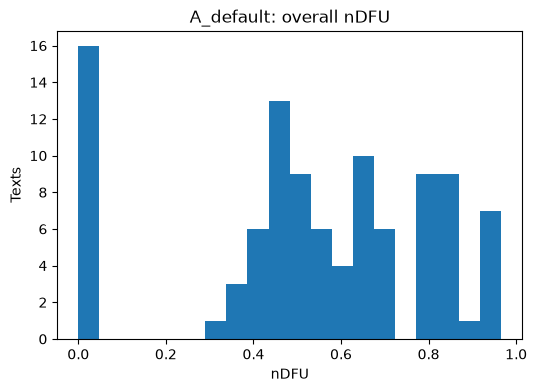

nDFU by k:
       mean       min       max  count
k                                     
0  0.000836  0.000000  0.012552     16
1  0.535441  0.305355  0.863976     18
2  0.621778  0.433839  0.867322     33
3  0.638928  0.347902  0.965473     19
4  0.778485  0.451977  0.955808     14


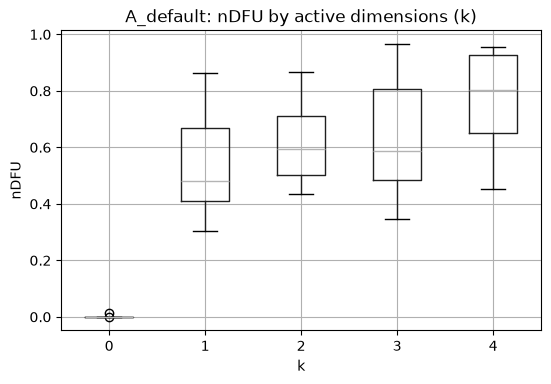


B_weak_signal nDFU summary
count    100.000000
mean       0.455286
std        0.257874
min        0.000000
25%        0.337559
50%        0.463207
75%        0.644959
max        0.914365
Name: ndfu, dtype: float64


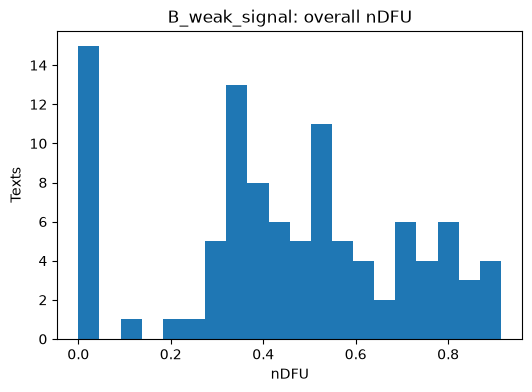

nDFU by k:
       mean       min       max  count
k                                     
0  0.000450  0.000000  0.005021     15
1  0.397832  0.124000  0.777595     30
2  0.557120  0.283541  0.873938     18
3  0.636351  0.356546  0.914365     26
4  0.637596  0.358036  0.817150     11


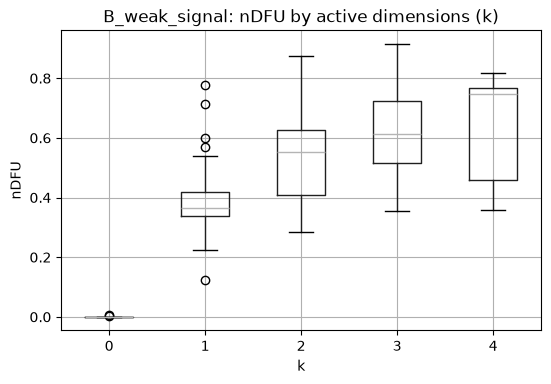


C_deep nDFU summary
count    100.000000
mean       0.560213
std        0.227509
min        0.000000
25%        0.461624
50%        0.568311
75%        0.706156
max        0.965736
Name: ndfu, dtype: float64


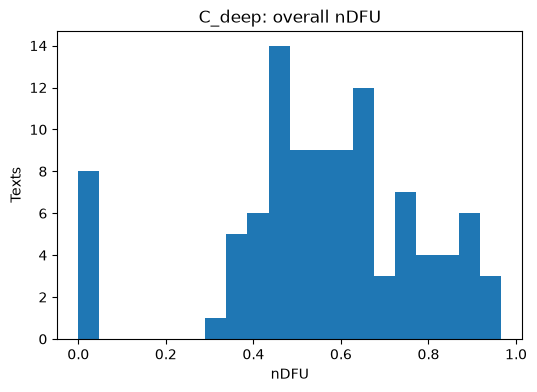

nDFU by k:
       mean       min       max  count
k                                     
0  0.000000  0.000000  0.000000      8
1  0.463441  0.331797  0.785374     17
2  0.629998  0.457726  0.846264     15
3  0.619604  0.360177  0.911582     19
4  0.656595  0.340619  0.965736     41


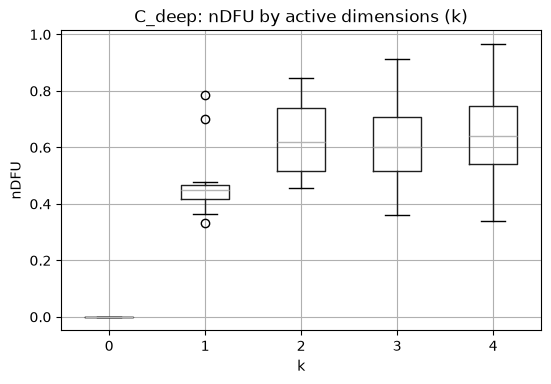


D_strong_signal nDFU summary
count    100.000000
mean       0.487557
std        0.278768
min        0.000000
25%        0.418842
50%        0.489668
75%        0.664258
max        0.965116
Name: ndfu, dtype: float64


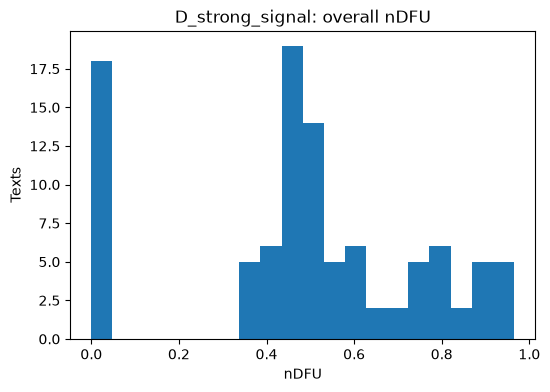

nDFU by k:
       mean       min       max  count
k                                     
0  0.000645  0.000000  0.004205     18
1  0.532554  0.374840  0.912869     31
2  0.602744  0.443595  0.884196     20
3  0.662038  0.366111  0.965116     25
4  0.604847  0.354727  0.914005      6


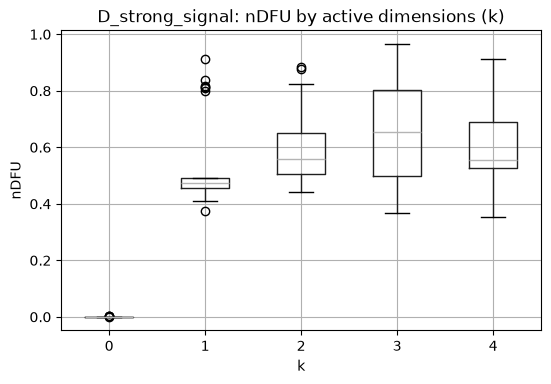


E_very_weak nDFU summary
count    100.000000
mean       0.441975
std        0.193571
min        0.000000
25%        0.338714
50%        0.420754
75%        0.564072
max        0.891304
Name: ndfu, dtype: float64


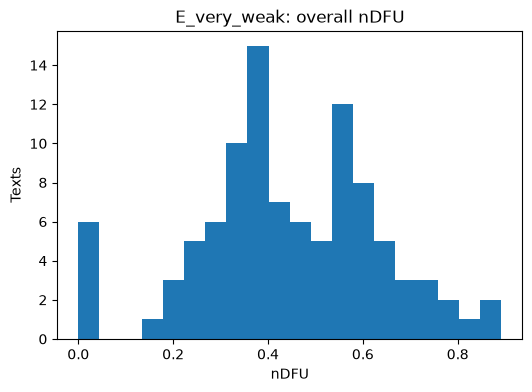

nDFU by k:
       mean       min       max  count
k                                     
0  0.000000  0.000000  0.000000      6
1  0.317820  0.168986  0.561728     32
2  0.559830  0.358548  0.776488     21
3  0.528964  0.338762  0.859281     30
4  0.581989  0.410405  0.891304     11


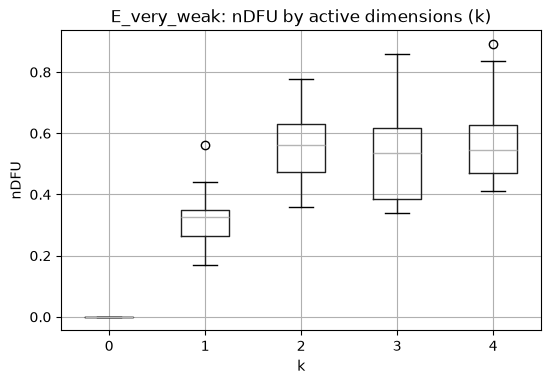


F_shallow nDFU summary
count    100.000000
mean       0.348488
std        0.295590
min        0.000000
25%        0.000000
50%        0.388815
75%        0.539280
max        0.937904
Name: ndfu, dtype: float64


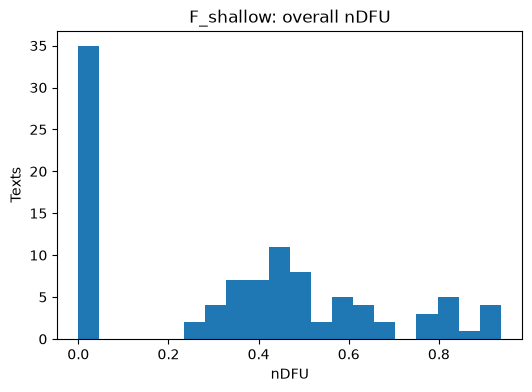

nDFU by k:
       mean       min       max  count
k                                     
0  0.000374  0.000000  0.004638     35
1  0.455786  0.259762  0.937904     38
2  0.618387  0.354877  0.891925     20
3  0.696387  0.476476  0.909091      4
4  0.787515  0.613071  0.908755      3


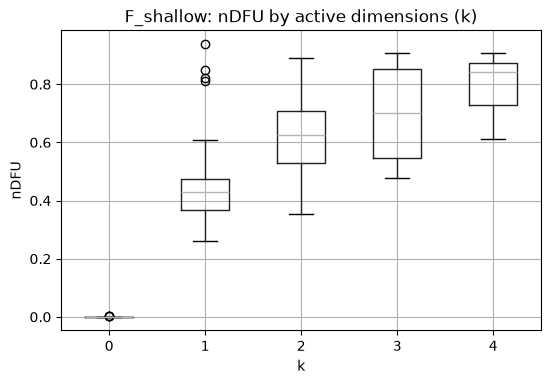


G_uniform_depth nDFU summary
count    100.000000
mean       0.405274
std        0.316603
min        0.000000
25%        0.000825
50%        0.478830
75%        0.619494
max        0.957364
Name: ndfu, dtype: float64


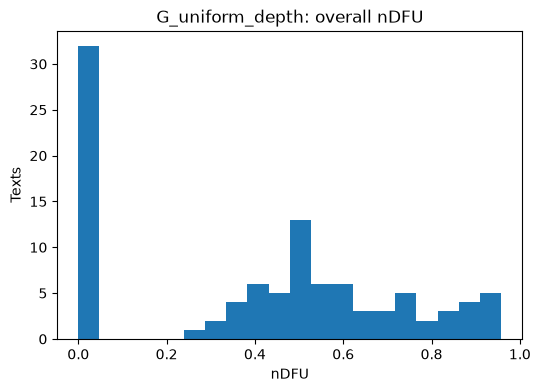

nDFU by k:
       mean       min       max  count
k                                     
0  0.000872  0.000000  0.007488     32
1  0.508689  0.273906  0.957364     18
2  0.593705  0.332509  0.902307     15
3  0.660944  0.413498  0.953488     17
4  0.622304  0.376543  0.943538     18


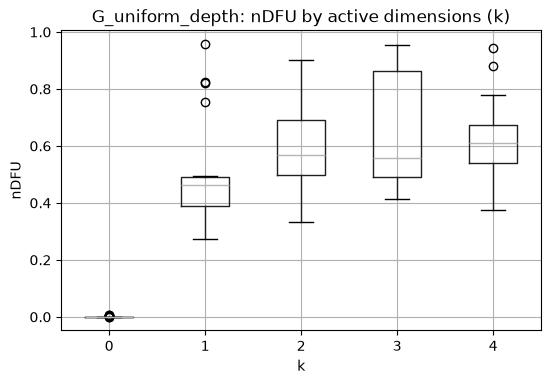


H_deep_weak nDFU summary
count    100.000000
mean       0.573515
std        0.217751
min        0.000000
25%        0.414031
50%        0.593535
75%        0.746965
max        0.959583
Name: ndfu, dtype: float64


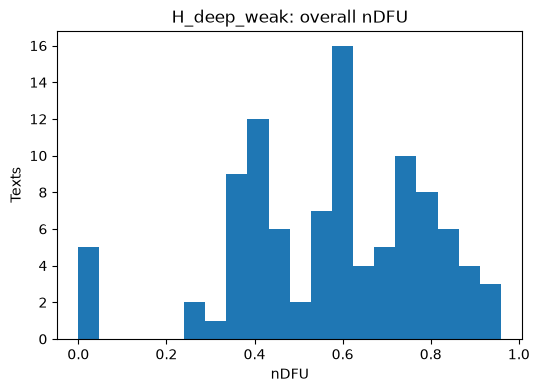

nDFU by k:
       mean       min       max  count
k                                     
0  0.000000  0.000000  0.000000      5
1  0.379183  0.251923  0.584980      8
2  0.582220  0.344371  0.822823     27
3  0.647622  0.369048  0.914667     24
4  0.640422  0.369328  0.959583     36


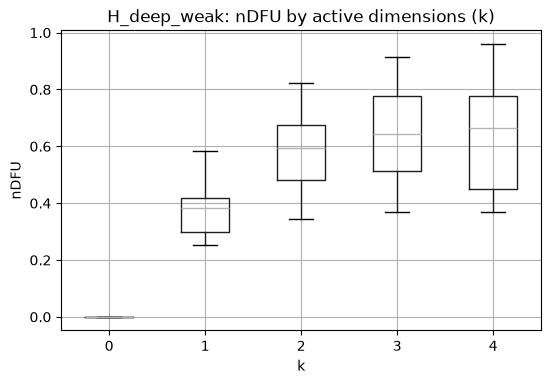


I_deep_strong nDFU summary
count    100.000000
mean       0.584295
std        0.213765
min        0.000000
25%        0.478946
50%        0.568729
75%        0.712495
max        0.957286
Name: ndfu, dtype: float64


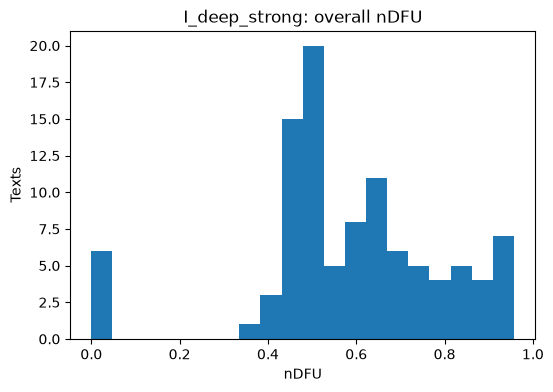

nDFU by k:
       mean       min       max  count
k                                     
0  0.000000  0.000000  0.000000      6
1  0.469670  0.434307  0.496054      8
2  0.595677  0.459223  0.828537     21
3  0.628548  0.371353  0.955752     36
4  0.673627  0.421435  0.957286     29


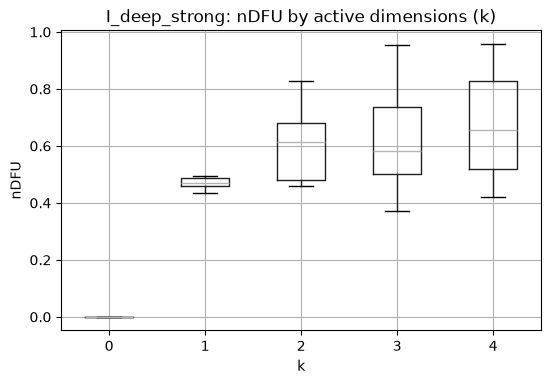


J_shallow_weak nDFU summary
count    100.000000
mean       0.309507
std        0.232531
min        0.000000
25%        0.004188
50%        0.328836
75%        0.433755
max        0.811966
Name: ndfu, dtype: float64


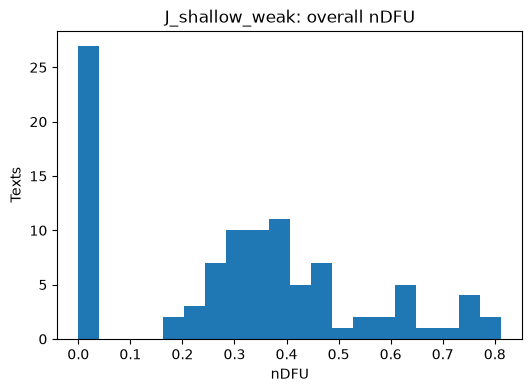

nDFU by k:
       mean       min       max  count
k                                     
0  0.000587  0.000000  0.004476     27
1  0.355880  0.171674  0.745704     50
2  0.540883  0.344828  0.811966     15
3  0.636758  0.540966  0.698701      6
4  0.603530  0.449304  0.757757      2


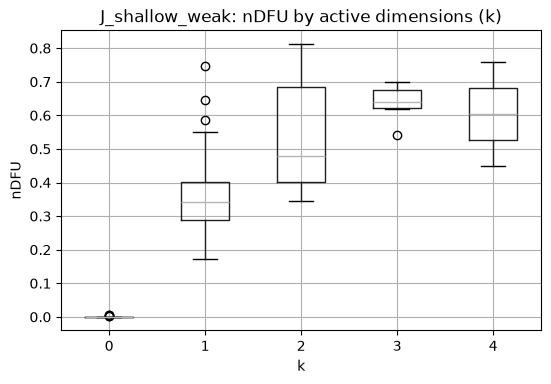


inference_unseen nDFU summary
count    100.000000
mean       0.525977
std        0.259701
min        0.000000
25%        0.437230
50%        0.534402
75%        0.719608
max        0.969849
Name: ndfu, dtype: float64


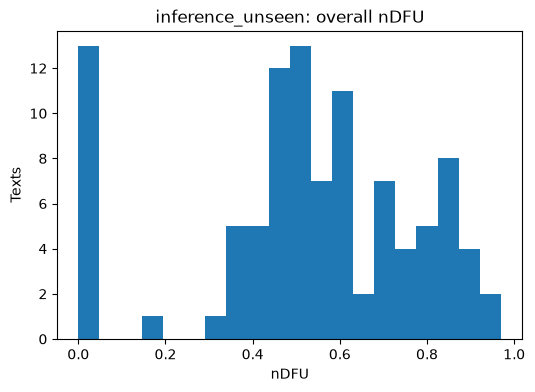

nDFU by k:
       mean       min       max  count
k                                     
0  0.000068  0.000000  0.000883     13
1  0.517689  0.183178  0.896409     31
2  0.631409  0.400471  0.951316     21
3  0.656271  0.380425  0.969849     24
4  0.685310  0.464627  0.847356     11


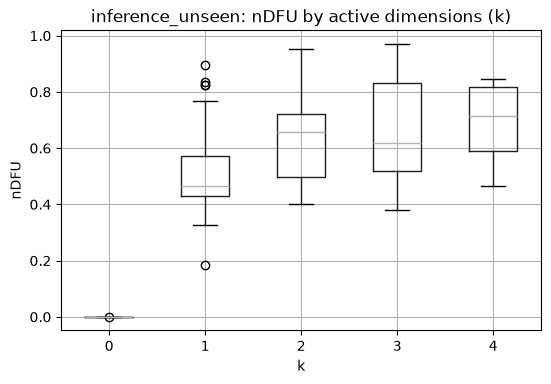

In [10]:
from ndfu import dfu

def ndfu_for_histogram(hist):
    hist = np.asarray(hist, dtype=float)
    total = hist.sum()
    if total == 0:
        return np.nan

    p = hist / total
    value = dfu(p)

    # Support either a scalar DFU-like return or a tuple/dict containing
    # the normalized score, depending on the installed ndFu version.
    if np.isscalar(value):
        return float(value)

    if isinstance(value, dict):
        for key in ("ndfu", "nDFU", "dfu"):
            if key in value:
                return float(value[key])

    if isinstance(value, (tuple, list, np.ndarray)):
        arr = np.asarray(value).ravel()
        if arr.size == 1:
            return float(arr[0])

    raise TypeError(
        "Could not interpret ndFu.dfu output. Inspect `dfu(...)` and "
        "adapt only this helper to the installed ndFu version."
    )


def overall_ndfu(dataset, scale):
    out = []

    for text_id, group in dataset.groupby("text_id", sort=True):
        counts = (
            group["rating"]
            .value_counts()
            .reindex(range(1, scale + 1), fill_value=0)
            .to_numpy()
        )
        out.append((text_id, ndfu_for_histogram(counts)))

    return pd.DataFrame(out, columns=["text_id", "ndfu"])


for name in corpora:
    nd = overall_ndfu(corpora[name]["dataset"], SCALE)

    gt = corpora[name]["ground_truth"]
    nd["k"] = nd["text_id"].map(
        lambda t: len(gt[int(t)]["active_dims"])
    )

    print(f"\n{name} nDFU summary")
    print(nd["ndfu"].describe())

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(nd["ndfu"].dropna(), bins=20)
    ax.set_xlabel("nDFU")
    ax.set_ylabel("Texts")
    ax.set_title(f"{name}: overall nDFU")
    plt.show()

    print("nDFU by k:")
    print(nd.groupby("k")["ndfu"].agg(["mean", "min", "max", "count"]))

    fig, ax = plt.subplots(figsize=(6, 4))
    nd.boxplot(column="ndfu", by="k", ax=ax)
    ax.set_title(f"{name}: nDFU by active dimensions (k)")
    ax.set_xlabel("k")
    ax.set_ylabel("nDFU")
    plt.suptitle("")
    plt.show()

In [11]:
ndfu_data = {}

for name in corpora:
    nd = overall_ndfu(corpora[name]["dataset"], SCALE)
    ndfu_data[name] = nd["ndfu"].dropna().to_numpy()

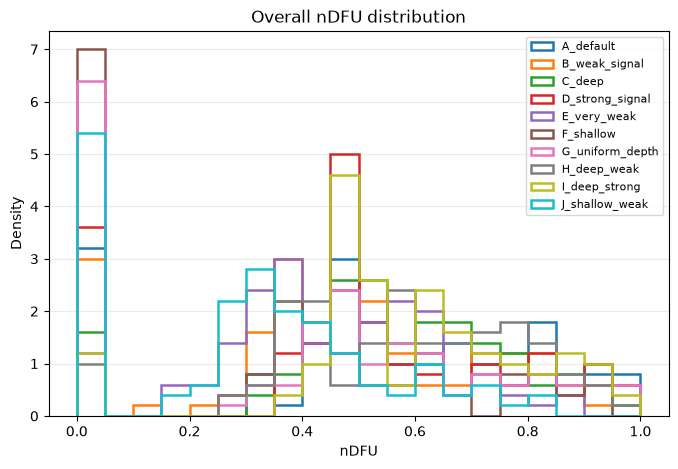

In [12]:
colors = plt.cm.tab10.colors

fig, ax = plt.subplots(figsize=(8, 5))

for color, name in zip(colors, EVALUATION_CORPORA):
    ax.hist(
        ndfu_data[name],
        bins=20,
        range=(0, 1),
        density=True,
        histtype="step",
        linewidth=1.8,
        color=color,
        label=name,
    )

ax.set_xlabel("nDFU")
ax.set_ylabel("Density")
ax.set_title("Overall nDFU distribution")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.25)

plt.show()


In [13]:
colors = plt.cm.tab10.colors
labels = EVALUATION_CORPORA

benchmark_names = EVALUATION_CORPORA

ndfu_k_data = {}

for name in benchmark_names:
    nd = overall_ndfu(corpora[name]["dataset"], SCALE)

    gt = corpora[name]["ground_truth"]

    nd["k"] = nd["text_id"].map(
        lambda t: len(gt[int(t)]["active_dims"])
    )

    nd = nd.dropna(subset=["ndfu", "k"])
    nd["k"] = nd["k"].astype(int)

    ndfu_k_data[name] = nd

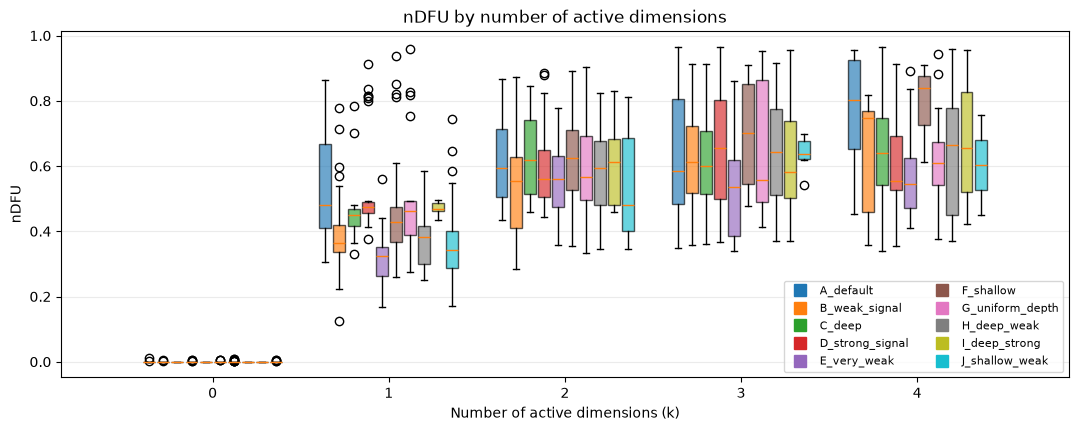

In [14]:
ks = sorted(
    set().union(
        *[
            df["k"].unique()
            for df in ndfu_k_data.values()
        ]
    )
)

n_corpora = len(benchmark_names)
box_width = 0.8 / n_corpora

fig, ax = plt.subplots(figsize=(13, 4.5))

positions = []
box_data = []
box_colors = []

for i, k in enumerate(ks):
    for j, name in enumerate(benchmark_names):

        values = ndfu_k_data[name].loc[
            ndfu_k_data[name]["k"] == k,
            "ndfu"
        ]

        if len(values) == 0:
            continue

        positions.append(
            i + 1 + (j - (n_corpora - 1) / 2) * box_width
        )

        box_data.append(values)
        box_colors.append(colors[j])

bp = ax.boxplot(
    box_data,
    positions=positions,
    widths=box_width * 0.85,
    patch_artist=True,
)

for patch, color in zip(bp["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

ax.set_xticks(range(1, len(ks) + 1))
ax.set_xticklabels(ks)

ax.set_xlabel("Number of active dimensions (k)")
ax.set_ylabel("nDFU")
ax.set_title("nDFU by number of active dimensions")

handles = [
    plt.Line2D(
        [0], [0],
        color=color,
        marker="s",
        linestyle="",
        markersize=8,
        label=label,
    )
    for color, label in zip(colors, labels)
]

ax.legend(handles=handles, fontsize=8, ncol=2)
ax.grid(axis="y", alpha=0.25)

plt.show()


## 6. Active-dimension balance

The synthetic benchmark should not systematically favor one demographic dimension. This check uses the stored ground truth and shows how often each dimension is active across each corpus.

In [15]:
rows = []

for name in EVALUATION_CORPORA:
    gt = corpora[name]["ground_truth"]

    counts = {dim: 0 for dim in DIMS}
    total_texts = len(gt)

    for cfg in gt.values():
        for dim in cfg["active_dims"]:
            counts[dim] += 1

    for dim, count in counts.items():
        rows.append({
            "corpus": name,
            "dimension": dim,
            "active_texts": count,
            "frequency": count / total_texts,
        })

active_df = pd.DataFrame(rows)
display(active_df.pivot(index="dimension", columns="corpus", values="frequency"))

corpus,A_default,B_weak_signal,C_deep,D_strong_signal,E_very_weak,F_shallow,G_uniform_depth,H_deep_weak,I_deep_strong,J_shallow_weak
dimension,,,,,,,,,,
age,0.39,0.35,0.59,0.36,0.42,0.24,0.34,0.49,0.56,0.26
education,0.36,0.43,0.50,0.41,0.45,0.24,0.34,0.66,0.45,0.24
gender,0.41,0.33,0.54,0.31,0.40,0.15,0.31,0.48,0.55,0.25
orientation,0.43,0.42,0.50,0.24,0.36,0.24,0.35,0.53,0.64,0.15
politics,0.38,0.35,0.55,0.38,0.45,0.15,0.37,0.62,0.54,0.16


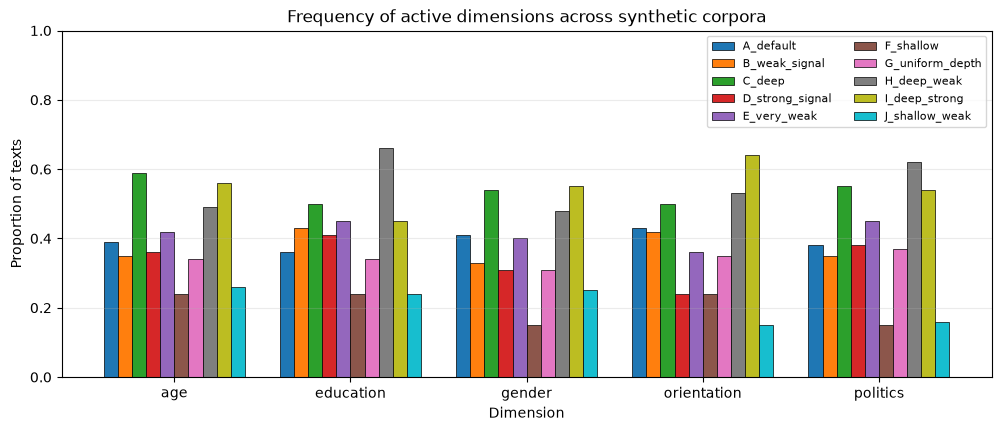

In [16]:
colors = plt.cm.tab10.colors
labels = EVALUATION_CORPORA

# Keep the corpus order fixed
active_pivot = active_df.pivot(
    index="dimension",
    columns="corpus",
    values="frequency",
).reindex(columns=EVALUATION_CORPORA)

fig, ax = plt.subplots(figsize=(12, 4.5))

x = np.arange(len(active_pivot.index))
n_corpora = len(EVALUATION_CORPORA)
width = 0.8 / n_corpora

for i, (corpus, color, label) in enumerate(
    zip(active_pivot.columns, colors, labels)
):
    ax.bar(
        x + (i - (n_corpora - 1) / 2) * width,
        active_pivot[corpus],
        width,
        color=color,
        edgecolor="black",
        linewidth=0.5,
        label=label,
    )

ax.set_xticks(x)
ax.set_xticklabels(active_pivot.index)
ax.set_ylabel("Proportion of texts")
ax.set_xlabel("Dimension")
ax.set_title("Frequency of active dimensions across synthetic corpora")

ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)
ax.legend(fontsize=8, ncol=2)

plt.show()


## 7. Ready for benchmark

At this point the synthetic environment has produced eleven fixed corpora:

- `A_default`, `B_weak_signal`, `C_deep`: the three corpora of the paper, **model-selection corpora**
- `D_strong_signal`, `E_very_weak`, `F_shallow`, `G_uniform_depth`, `H_deep_weak`, `I_deep_strong`, `J_shallow_weak`: **more model-selection corpora with ground truth**, so the hyperparameter search runs on all ten
- `inference_unseen`: **held-out inference corpus**

The next notebook reads these files, runs the randomized hyperparameter search on A to J, selects the configuration by mean Jaccard, and then runs the selected configuration on `inference_unseen` **without ground truth** to obtain F, C, P, and diagnostics.

In [17]:
from pathlib import Path
import shutil

# ============================================================
# Package the generated synthetic benchmark data
# ============================================================

BUNDLE_DIR = PROJECT_ROOT / "synthetic_benchmark_bundle"

# Start from a clean bundle
if BUNDLE_DIR.exists():
    shutil.rmtree(BUNDLE_DIR)

BUNDLE_DATA_DIR = BUNDLE_DIR / "benchmark_data"
BUNDLE_DATA_DIR.mkdir(parents=True)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"{DATA_DIR} was not found."
    )

for path in DATA_DIR.iterdir():
    if path.is_file():
        shutil.copy2(path, BUNDLE_DATA_DIR / path.name)

print("Synthetic benchmark bundle:")
for path in sorted(BUNDLE_DIR.rglob("*")):
    if path.is_file():
        print(f"  {path.relative_to(BUNDLE_DIR)}")

ZIP_PATH = shutil.make_archive(
    str(PROJECT_ROOT / "synthetic_benchmark_bundle"),
    "zip",
    root_dir=PROJECT_ROOT,
    base_dir=BUNDLE_DIR.name,
)

print(f"\nCreated: {ZIP_PATH}")
print(
    f"Size: {Path(ZIP_PATH).stat().st_size / 1024**2:.2f} MB"
)
print("The ZIP is in the project root.")


Synthetic benchmark bundle:
  benchmark_data\A_default_config.json
  benchmark_data\A_default_dataset.csv
  benchmark_data\A_default_ground_truth.json
  benchmark_data\B_weak_signal_config.json
  benchmark_data\B_weak_signal_dataset.csv
  benchmark_data\B_weak_signal_ground_truth.json
  benchmark_data\C_deep_config.json
  benchmark_data\C_deep_dataset.csv
  benchmark_data\C_deep_ground_truth.json
  benchmark_data\D_strong_signal_config.json
  benchmark_data\D_strong_signal_dataset.csv
  benchmark_data\D_strong_signal_ground_truth.json
  benchmark_data\E_very_weak_config.json
  benchmark_data\E_very_weak_dataset.csv
  benchmark_data\E_very_weak_ground_truth.json
  benchmark_data\F_shallow_config.json
  benchmark_data\F_shallow_dataset.csv
  benchmark_data\F_shallow_ground_truth.json
  benchmark_data\G_uniform_depth_config.json
  benchmark_data\G_uniform_depth_dataset.csv
  benchmark_data\G_uniform_depth_ground_truth.json
  benchmark_data\H_deep_weak_config.json
  benchmark_data\H_deep_w